# Arrivals in Jamaica by African region of embarkation, by decade

About a million enslaved Africans were landed in Jamaica. This notebook asks where on the
African coast they were embarked, decade by decade, and how the answer depends on the source:

- **Recorded**: numbers transcribed from historical documents. For each voyage that landed
  captives in Jamaica, the number of captives arriving at the first place of landing
  (SLAARRIV), with the African region taken from the recorded principal place of purchase.
  Public domain.
- **Imputed**: the voyage database's imputed totals (SLAMIMP) and imputed principal places,
  which fill gaps in the record voyage by voyage. CC BY-NC 4.0.
- **Estimates**: the 2010 Estimates, which model the whole trade, including voyages that left
  no record. CC BY-NC 4.0.

Read the gaps between the three as a measure of what the surviving records do not show,
not as errors in any one of them.

Needs the full data: `uv run voyages fetch && uv run voyages build`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

import voyages
from voyages import Voyages

v = Voyages()

## Regions

The voyage data and the Estimates name the African regions slightly differently, and use
different codes. The eight regions correspond one to one. "Other Africa" in the voyage data
means the record does not say where in Africa the captives were embarked; the Estimates have
no such category, because they assign every captive to a region.

In [2]:
REGIONS = pd.DataFrame(
    [
        (60100, 1, "Senegambia"),
        (60200, 2, "Sierra Leone"),
        (60300, 3, "Windward Coast"),
        (60400, 4, "Gold Coast"),
        (60500, 5, "Bight of Benin"),
        (60600, 6, "Bight of Biafra"),
        (60700, 7, "West Central Africa"),
        (60800, 8, "South-east Africa"),
    ],
    columns=["voyage_region", "estimates_region", "region"],
)
UNKNOWN = "Region not known"

names = REGIONS.assign(
    voyage_name=REGIONS.voyage_region.map(
        v.sql("SELECT code, name FROM places").to_pandas().set_index("code").name
    ),
    estimates_name=REGIONS.estimates_region.map(
        v.table("estimates_embarkation_regions").to_pandas().set_index("code").label
    ),
)
# The short names are the Estimates labels; check the voyage names say the same thing.
assert (names.region == names.estimates_name).all()
assert all(
    n.split(" and ")[0].replace("Southeast", "South-east").startswith(r.split()[0])
    for n, r in zip(names.voyage_name, names.region, strict=True)
)
names[["region", "voyage_name", "estimates_name"]]

,region,voyage_name,estimates_name
0,Senegambia,Senegambia and offshore Atlantic,Senegambia
1,Sierra Leone,Sierra Leone,Sierra Leone
2,Windward Coast,Windward Coast,Windward Coast
3,Gold Coast,Gold Coast,Gold Coast
4,Bight of Benin,Bight of Benin,Bight of Benin
5,Bight of Biafra,Bight of Biafra and Gulf of Guinea islands,Bight of Biafra
6,West Central Africa,West Central Africa and St. Helena,West Central Africa
7,South-east Africa,Southeast Africa and Indian Ocean islands,South-east Africa


In [3]:
def short_region(code):
    """Voyage region code -> the short region name, or 'Region not known'."""
    lookup = REGIONS.set_index("voyage_region").region
    return lookup.get(code, UNKNOWN) if pd.notna(code) else UNKNOWN

## Three sources, one shape

Each source becomes a table of decade x region x people. Decades follow the year of arrival:
the imputed year (YEARAM) for the imputed data and the Estimates, and the recorded year of
first landing for the recorded data.

In [4]:
imputed = (
    v.transatlantic.disembarked_in("Jamaica")
    .by_decade(["voyages", "disembarked"], by="embarkation_region")
    .assign(region=lambda d: d.embarkation_region.map(short_region), source="Imputed")
    .rename(columns={"disembarked": "people"})
)

recorded = (
    v.transatlantic.recorded_only()
    .disembarked_in("Jamaica")
    .by_decade(["voyages", "captives_arrived_first_landing"], by="embarkation_region")
    .assign(region=lambda d: d.embarkation_region.map(short_region), source="Recorded")
    .rename(columns={"captives_arrived_first_landing": "people"})
)

estimates = (
    v.sql(
        """
        SELECT (year // 10 * 10)::SMALLINT AS decade, embarkation_region AS estimates_region,
               sum(disembarked_estimated_total) AS people
        FROM estimates
        WHERE disembarkation_region = (
            SELECT code FROM estimates_disembarkation_regions WHERE label = 'Jamaica')
        GROUP BY ALL
        """
    )
    .to_pandas()
    .merge(REGIONS[["estimates_region", "region"]], how="left")
    .assign(region=lambda d: d.region.fillna(UNKNOWN), source="Estimates", voyages=pd.NA)
)

cols = ["source", "decade", "region", "voyages", "people"]
long = pd.concat([estimates[cols], imputed[cols], recorded[cols]], ignore_index=True)
long["people"] = long.people.fillna(0).astype(int)

### Checks

The Estimates table reproduces the site's total embarked (12,521,337 on
https://legacy.slavevoyages.org/assessment/estimates, checked 2026-10-19; the `.sav` rounds
each row, see docs/DATA.md). Each source's regional rows add up to its own total.

In [5]:
total_embarked = v.sql("SELECT sum(embarked_estimated_total) FROM estimates").relation.fetchone()[0]
assert abs(total_embarked - 12_521_337) <= 20, total_embarked

imp_total = v.transatlantic.disembarked_in("Jamaica").summary().disembarked.item()
assert imputed.people.sum() == imp_total
rec_summary = v.transatlantic.recorded_only().disembarked_in("Jamaica").summary()
assert recorded.people.sum() == rec_summary.captives_arrived_first_landing.item()
assert (estimates.region != UNKNOWN).all()  # the Estimates assign every captive to a region

## Totals by region

In [6]:
by_region = long.pivot_table(
    index="region", columns="source", values="people", aggfunc="sum", fill_value=0
)[["Recorded", "Imputed", "Estimates"]]
order = [*REGIONS.region, UNKNOWN]
by_region = by_region.reindex(order).fillna(0).astype(int)
by_region.loc["Total"] = by_region.sum()
by_region

source,Recorded,Imputed,Estimates
region,,,
Senegambia,10136,16247,29705
Sierra Leone,17856,26270,34317
Windward Coast,17530,29949,41053
Gold Coast,152301,200135,301576
Bight of Benin,63586,82287,128110
Bight of Biafra,186377,230965,296599
West Central Africa,100317,122423,179914
South-east Africa,556,1018,8314
Region not known,136306,225283,0


How many voyages lie behind the voyage-based columns, and how many of the recorded voyages
have a count of captives at all:

In [7]:
coverage = pd.DataFrame(
    {
        "voyages": [rec_summary.voyages.item(), imputed.voyages.sum()],
        "voyages with a count": [
            rec_summary.voyages_with_captives_arrived_first_landing.item(),
            v.transatlantic.disembarked_in("Jamaica").summary().voyages_with_disembarked.item(),
        ],
    },
    index=["Recorded", "Imputed"],
)
coverage

,voyages,voyages with a count
Recorded,3519,2512
Imputed,3591,3589


## By decade

Chart conventions: one colour per source in every chart (Estimates blue, imputed orange,
recorded aqua and dashed), people in thousands, one y-axis per panel.

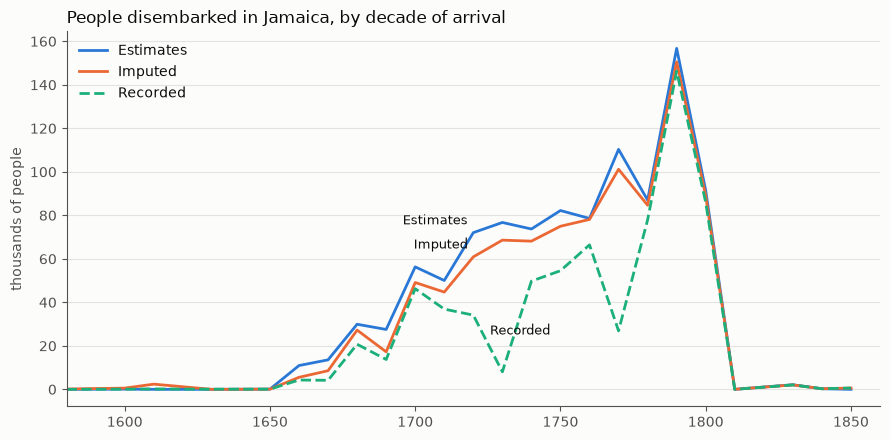

In [8]:
COLORS = {"Estimates": "#2a78d6", "Imputed": "#eb6834", "Recorded": "#1baf7a"}
STYLES = {"Estimates": "-", "Imputed": "-", "Recorded": "--"}
SURFACE, INK, MUTED = "#fcfcfb", "#0b0b0b", "#52514e"

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": "#e4e3df",
        "grid.linewidth": 0.8,
        "font.size": 10,
    }
)

by_decade = (
    long.dropna(subset=["decade"])
    .pivot_table(index="decade", columns="source", values="people", aggfunc="sum", fill_value=0)
    .sort_index()
)
fig, ax = plt.subplots(figsize=(9, 4.5))
for source in ["Estimates", "Imputed", "Recorded"]:
    s = by_decade[source] / 1000
    ax.plot(s.index, s.values, STYLES[source], color=COLORS[source], linewidth=2, label=source)
    # Direct labels where the three lines sit well apart.
    below = source == "Recorded"
    ax.annotate(
        source, (1720, s.loc[1720]), xytext=(12 if below else -4, -14 if below else 6),
        textcoords="offset points", ha="left" if below else "right", color=INK, fontsize=9,
    )  # fmt: skip
ax.set_title("People disembarked in Jamaica, by decade of arrival", loc="left", color=INK)
ax.set_ylabel("thousands of people")
ax.set_xlim(by_decade.index.min(), by_decade.index.max() + 10)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig("figures/01_jamaica_by_decade.png", dpi=150)

In [9]:
by_decade.astype(int)

source,Estimates,Imputed,Recorded
decade,,,
1580,0,150,0
1600,97,564,97
1610,0,2391,186
1630,0,0,68
1650,94,85,85
1660,10941,5530,4287
1670,13560,8562,4148
1680,29927,27244,20729
1690,27534,17240,13729


The recorded line drops in the 1730s and 1770s. Few of that decade's voyages have a
transcribed count of captives arriving, although the voyages themselves are known:

In [10]:
v.sql(
    """
    SELECT (year_arrived_imputed // 10 * 10)::SMALLINT AS decade,
           count(*) AS voyages,
           count(captives_arrived_first_landing) AS with_recorded_count
    FROM voyages_wide JOIN voyage_endpoints USING (voyage_id, dataset)
    WHERE dataset = 'transatlantic' AND disembarkation_region = 35100
      AND year_arrived_imputed BETWEEN 1700 AND 1809
    GROUP BY 1 ORDER BY 1
    """
).to_pandas().assign(share=lambda d: (d.with_recorded_count / d.voyages).round(2))

,decade,voyages,with_recorded_count,share
0,1700,223,209,0.94
1,1710,194,156,0.80
2,1720,261,138,0.53
3,1730,303,35,0.12
4,1740,270,189,0.70
5,1750,328,250,0.76
6,1760,323,271,0.84
7,1770,386,95,0.25
8,1780,230,209,0.91
9,1790,507,490,0.97


## By region and decade

One panel per region, same scale throughout so the panels compare. In the voyage data, the
last panel holds the captives whose region of embarkation is not known; the Estimates have
assigned all of them to the eight regions.

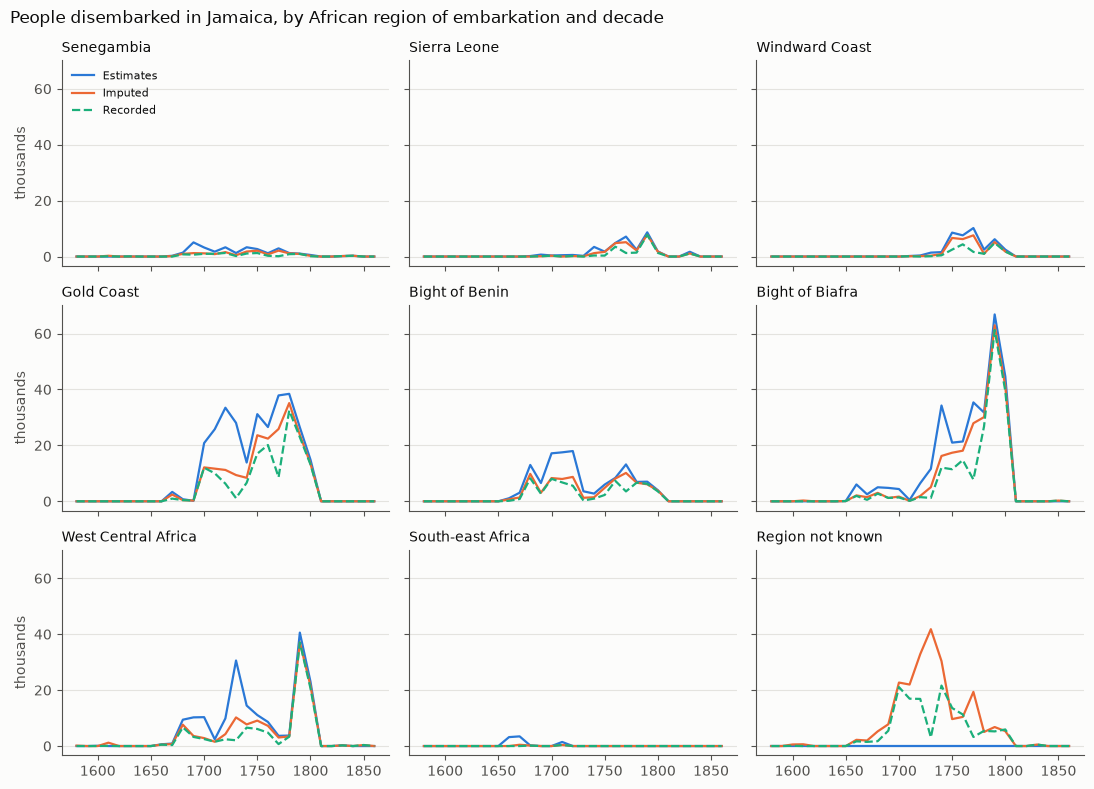

In [11]:
grid = long.dropna(subset=["decade"]).pivot_table(
    index=["region", "decade"], columns="source", values="people", aggfunc="sum", fill_value=0
)
decades = range(int(grid.index.get_level_values("decade").min()), 1870, 10)
fig, axes = plt.subplots(3, 3, figsize=(11, 8), sharex=True, sharey=True)
for ax, region in zip(axes.flat, order, strict=True):
    panel = grid.loc[region].reindex(decades, fill_value=0) if region in grid.index else None
    for source in ["Estimates", "Imputed", "Recorded"]:
        if panel is not None and source in panel:
            ax.plot(
                panel.index,
                panel[source] / 1000,
                STYLES[source],
                color=COLORS[source],
                linewidth=1.6,
                label=source,
            )
    ax.set_title(region, loc="left", fontsize=10, color=INK)
for ax in axes[:, 0]:
    ax.set_ylabel("thousands")
axes[0, 0].legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle(
    "People disembarked in Jamaica, by African region of embarkation and decade",
    x=0.01,
    ha="left",
    color=INK,
)
fig.tight_layout()
fig.savefig("figures/01_jamaica_by_region.png", dpi=150)

## Before 1700

Jamaica was Spanish until the English conquest of 1655. The voyage database has a handful of
voyages to Spanish Jamaica; the Estimates show almost none. After 1655 the numbers grow, but
stay small next to the eighteenth century.

In [12]:
early = (
    by_decade.loc[:1690]
    .astype(int)
    .join(imputed.groupby("decade").voyages.sum().rename("imputed voyages").astype(int))
)
early

,Estimates,Imputed,Recorded,imputed voyages
decade,,,,
1580,0,150,0,1.0
1600,97,564,97,2.0
1610,0,2391,186,9.0
1630,0,0,68,NaN
1650,94,85,85,1.0
1660,10941,5530,4287,21.0
1670,13560,8562,4148,37.0
1680,29927,27244,20729,110.0
1690,27534,17240,13729,65.0


## How the regions of embarkation changed

Shares of the people disembarked in Jamaica by region, in five periods. For the voyage
data, shares are of the people whose region is known; the last column says how many are
not. The four regions that supplied most people are charted, one panel each.

In [13]:
PERIODS = [(1650, 1699), (1700, 1729), (1730, 1759), (1760, 1789), (1790, 1809)]


def period_label(decade):
    for lo, hi in PERIODS:
        if lo <= decade <= hi:
            return f"{lo}-{hi}"
    return None


periods = long.assign(period=long.decade.map(period_label)).dropna(subset=["period"])
known = periods[periods.region != UNKNOWN]
shares = (
    known.pivot_table(
        index=["source", "period"], columns="region", values="people", aggfunc="sum", fill_value=0
    )
    .pipe(lambda t: t.div(t.sum(axis=1), axis=0) * 100)
    .reindex(columns=list(REGIONS.region))
)
unknown_share = (
    periods.assign(unknown=periods.region == UNKNOWN)
    .groupby(["source", "period"])
    .apply(lambda g: g.people[g.unknown].sum() / g.people.sum() * 100, include_groups=False)
)
people = periods.groupby(["source", "period"]).people.sum()

estimates_shares = (
    shares.loc["Estimates"].round(0).astype(int).assign(people=people.loc["Estimates"])
)
estimates_shares

region,Senegambia,Sierra Leone,Windward Coast,Gold Coast,Bight of Benin,Bight of Biafra,West Central Africa,South-east Africa,people
period,,,,,,,,,
1650-1699,8,1,0,5,29,22,26,8,82056
1700-1729,5,1,0,45,30,6,13,1,178377
1730-1759,3,2,5,31,5,29,24,0,232620
1760-1789,2,5,7,37,10,32,6,0,275880
1790-1809,1,4,3,17,4,45,26,0,248168


In [14]:
comparison = pd.concat(
    {
        source: shares.loc[source]
        .round(0)
        .astype(int)
        .assign(**{"region not known (%)": unknown_share.loc[source].round(0).astype(int)})
        for source in ["Imputed", "Recorded"]
    }
)
comparison

region              Senegambia  Sierra Leone  Windward Coast  Gold Coast  \
         period                                                            
Imputed  1650-1699           6             0               0           7   
         1700-1729           5             1               0          45   
         1730-1759           3             2               6          32   
         1760-1789           2             5               6          36   
         1790-1809           1             4               3          16   
Recorded 1650-1699           4             0               0           5   
         1700-1729           5             1               0          45   
         1730-1759           3             1               4          34   
         1760-1789           1             4               5          40   
         1790-1809           0             4               3          16   

region              Bight of Benin  Bight of Biafra  West Central Africa  \
         period                                                            
Imputed  1650-1699              36               19                   30   
         1700-1729              32                5                   11   
         1730-1759               6               30                   21   
         1760-1789              11               33                    6   
         1790-1809               4               46                   26   
Recorded 1650-1699              37               20                   33   
         1700-1729              33                5                   10   
         1730-1759               5               33                   20   
         1760-1789              12               33                    6   
         1790-1809               4               46                   26   

region              South-east Africa  region not known (%)  
         period                                              
Imputed  1650-1699                  2                    29  
         1700-1729                  0                    50  
         1730-1759                  0                    39  
         1760-1789                  0                    13  
         1790-1809                  0                     5  
Recorded 1650-1699                  1                    24  
         1700-1729                  1                    47  
         1730-1759                  0                    34  
         1760-1789                  0                    12  
         1790-1809                  0                     5

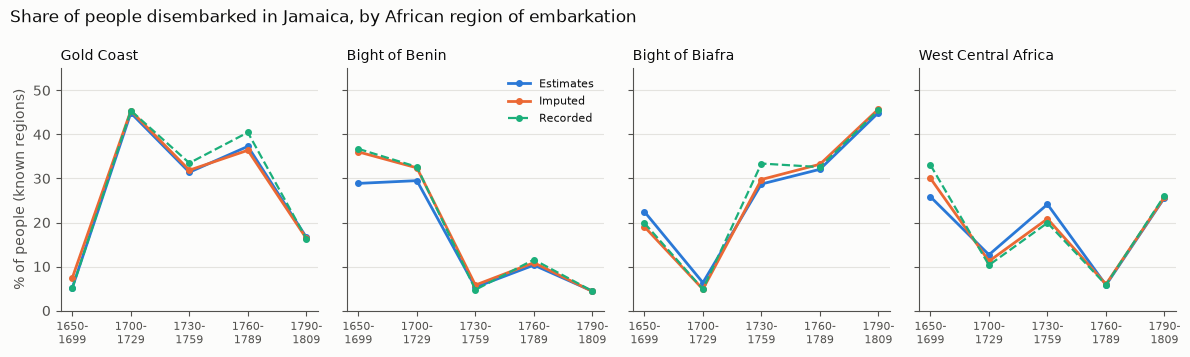

In [15]:
MAIN = ["Gold Coast", "Bight of Benin", "Bight of Biafra", "West Central Africa"]
labels = [f"{lo}-{hi}" for lo, hi in PERIODS]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.6), sharey=True)
for ax, region in zip(axes, MAIN, strict=True):
    for source in ["Estimates", "Imputed", "Recorded"]:
        y = shares.loc[source][region].reindex(labels)
        ax.plot(
            range(len(labels)), y.values, STYLES[source], color=COLORS[source],
            linewidth=2 if source != "Recorded" else 1.6, marker="o", markersize=4, label=source,
        )  # fmt: skip
    ax.set_title(region, loc="left", fontsize=10, color=INK)
    ax.set_xticks(range(len(labels)), [lab.replace("-", "-\n") for lab in labels], fontsize=8)
    ax.set_ylim(0, 55)
axes[0].set_ylabel("% of people (known regions)")
axes[1].legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle(
    "Share of people disembarked in Jamaica, by African region of embarkation",
    x=0.01, ha="left", color=INK,
)  # fmt: skip
fig.tight_layout()
fig.savefig("figures/01_jamaica_region_shares.png", dpi=150)

The voyage data and the Estimates tell the same story, and not by accident alone: the
Estimates are built from the voyage data, so their agreement is partly by construction.
Where half the voyage data has no known region (1700-1729), the Estimates' split leans on
their model.

## What the voyage records cover

The imputed voyage totals as a share of the Estimates, by decade: how much of the modelled
trade into Jamaica is accounted for by voyages in the database. Decades with fewer than
1,000 people in the Estimates are left out; their ratios are noise.

In [16]:
main = by_decade[by_decade.Estimates >= 1000]
pd.DataFrame(
    {
        "Estimates": main.Estimates.astype(int),
        "Imputed": main.Imputed.astype(int),
        "imputed / estimates": (main.Imputed / main.Estimates).round(2),
    }
)

,Estimates,Imputed,imputed / estimates
decade,,,
1660,10941,5530,0.51
1670,13560,8562,0.63
1680,29927,27244,0.91
1690,27534,17240,0.63
1700,56300,49106,0.87
1710,50046,44712,0.89
1720,72031,60898,0.85
1730,76707,68590,0.89
1740,73710,68123,0.92


In [17]:
# The figures quoted below, checked against the tables above.
imp, est = by_region["Imputed"], by_region["Estimates"]
known_gap = est["Total"] - (imp["Total"] - imp[UNKNOWN])
assert (imp[UNKNOWN], imp["Total"], est["Total"]) == (225_283, 934_577, 1_019_588)
assert est["Total"] - imp["Total"] == 85_011
assert 0.70 < imp[UNKNOWN] / known_gap < 0.75
assert set(est.drop(["Total", UNKNOWN]).nlargest(2).index) == {"Gold Coast", "Bight of Biafra"}
assert set(by_region["Recorded"].drop(["Total", UNKNOWN]).nlargest(2).index) == {
    "Gold Coast",
    "Bight of Biafra",
}
ratios = (main.Imputed / main.Estimates).loc[1700:1800]
assert 0.84 <= ratios.min() < 0.85 and 0.99 <= ratios.max() < 0.995

In [18]:
# Figures quoted below about periods.
assert early.loc[1580:1610, "imputed voyages"].sum() == 12
assert early.loc[1580:1610, "Imputed"].sum() == 3_105
assert people.loc[("Estimates", "1650-1699")] == 82_056
est_pct = shares.loc["Estimates"].round(0)
assert est_pct.loc["1700-1729", ["Gold Coast", "Bight of Benin"]].tolist() == [45, 30]
assert est_pct.loc["1730-1759", "Bight of Benin"] == 5
assert est_pct.loc["1790-1809", "Bight of Biafra"] == 45
assert (
    est_pct.loc["1650-1699", ["Bight of Benin", "West Central Africa", "Bight of Biafra"]].min()
    >= 22
)
gap = (shares.loc["Imputed"] - shares.loc["Estimates"])[MAIN].abs().max().max()
assert gap < 8, gap  # "within a few points"
assert round(unknown_share.loc[("Imputed", "1700-1729")]) == 50

## Reading the results

- The Gold Coast and the Bight of Biafra are the two largest known regions of embarkation in
  every column. The Estimates put them close together, at about 300,000 people each.
- In the imputed voyage data, 225,283 of the 934,577 people were on voyages whose African
  region is not known. The Estimates assign such captives to regions, so this accounts for
  nearly three quarters of the gap between the two columns for the eight regions. The rest,
  85,011 people, is the trade the Estimates add for voyages missing from the database.
- In each decade from 1700 to 1809, the peak of the trade into Jamaica, voyages in the
  database account for 84 to 99 per cent of the Estimates; the gap is widest before 1700.
- The regions changed over time. Before 1700 no single region dominated: the Bight of Benin,
  West Central Africa and the Bight of Biafra each supplied over a fifth. In 1700-1729 the
  Gold Coast (45 per cent) and the Bight of Benin (30 per cent) supplied three quarters.
  From the 1730s the Bight of Benin fell to 5 per cent and the Bight of Biafra rose; in the
  last decades before the British trade ended in 1807 it was the largest single region, at
  45 per cent. The voyage data gives the same shares within a few points.
- Before 1700: 12 voyages carried 3,105 people to Spanish Jamaica (1580s-1610s) in the
  voyage data; after the English conquest of 1655 the Estimates count 82,056 people to 1699.
- The recorded column is a floor, not an estimate: it counts only voyages with a transcribed
  number of captives arriving at the first landing, and that number survives unevenly (35 of
  307 voyages in the 1730s). Its regions follow the recorded place of purchase, which is
  missing more often than the imputed one.
- The Jamaica total in the Estimates (1,019,588) has not been checked against the site,
  whose estimates page needs its form to select Jamaica.

## Source and licence

Imputed variables and the Estimates are licensed CC BY-NC 4.0 by SlaveVoyages; the recorded
data is public domain. See NOTICE and docs/DATA.md.

In [19]:
print(voyages.citation())

SlaveVoyages, Trans-Atlantic Slave Trade Database, https://www.slavevoyages.org (accessed October 19, 2026).
